In [4]:
!pip install pywavelets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 16.3 MB/s eta 0:00:00


In [5]:
import pandas as pd
import numpy as np
import pywt
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
max([10,200])

200

## Creación de la señal

In [7]:
F1 = 20 #hz
F2 = 100 #hz

Fmax = lambda f1_,f2_: max([f1_, f2_])

Fs = 10*Fmax(F1,F2)
Ts = 1/Fs

print(f"Frecuencia 1: {F1} hz")
print(f"Frecuencia 2: {F2} hz")
print(f"Frecuencia max: {Fmax(F1,F2)} hz")
print(f"Frecuencia de muestreo 10*Fmax: {Fs} M/s")

Frecuencia 1: 20 hz
Frecuencia 2: 100 hz
Frecuencia max: 100 hz
Frecuencia de muestreo 10*Fmax: 1000 M/s


In [8]:
n = np.arange(0,1000)
t = n*Ts

In [9]:
x1 = 10*np.sin(2*np.pi*F1*t)
x2 = 10*np.sin(2*np.pi*F2*t)
x3 = x1+x2

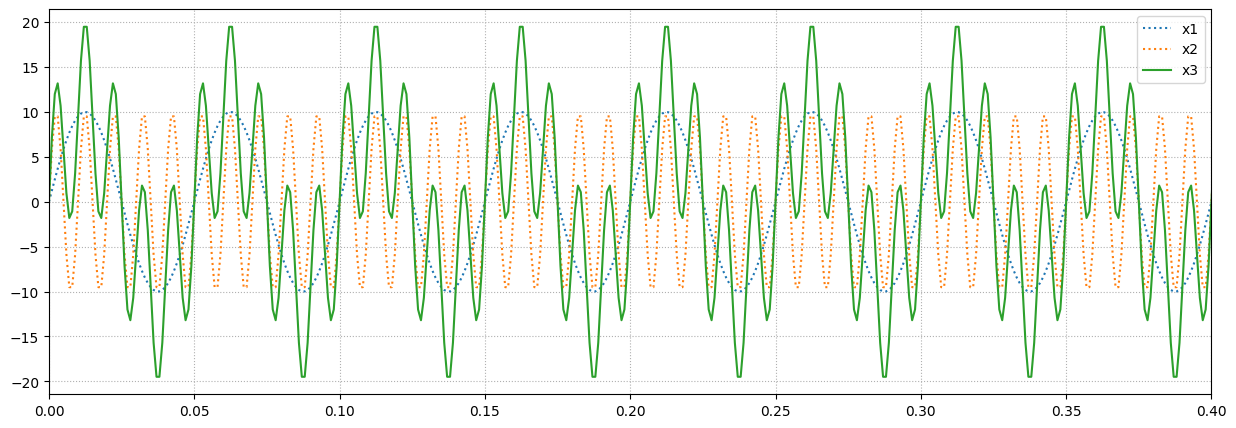

In [10]:
plt.figure(figsize=(15,5))
plt.plot(t,x1,label="x1", linestyle=":")
plt.plot(t,x2,label="x2", linestyle=":")
plt.plot(t,x3,label="x3")
plt.legend()
plt.grid(ls=":")
plt.xlim(0,0.4)
plt.show()

In [37]:
from scipy.io.wavfile import write


In [39]:
write("signal.wav", Fs, x3.astype(np.int16))


## Mostrar FFT

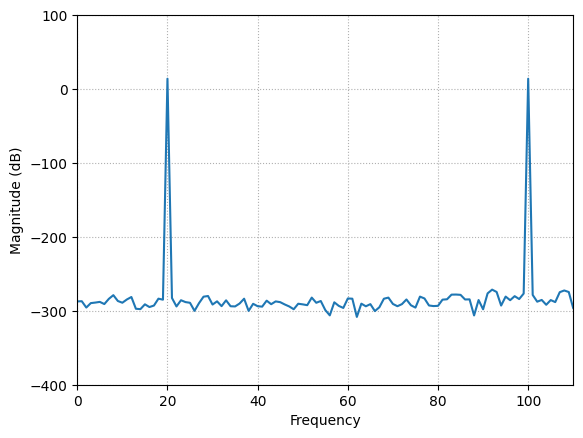

In [11]:
plt.magnitude_spectrum(x3, Fs=Fs, window=np.ones(x3.shape),scale="dB")# , sides='twosided')
plt.xlim(0,110)
plt.ylim(-400,100)
plt.grid(ls=":")
plt.show()

In [13]:
coeffs = pywt.wavedec(x3,'db6','sym',level=6)
(cA6,cD6,cD5,cD4,cD3,cD2,cD1) = coeffs

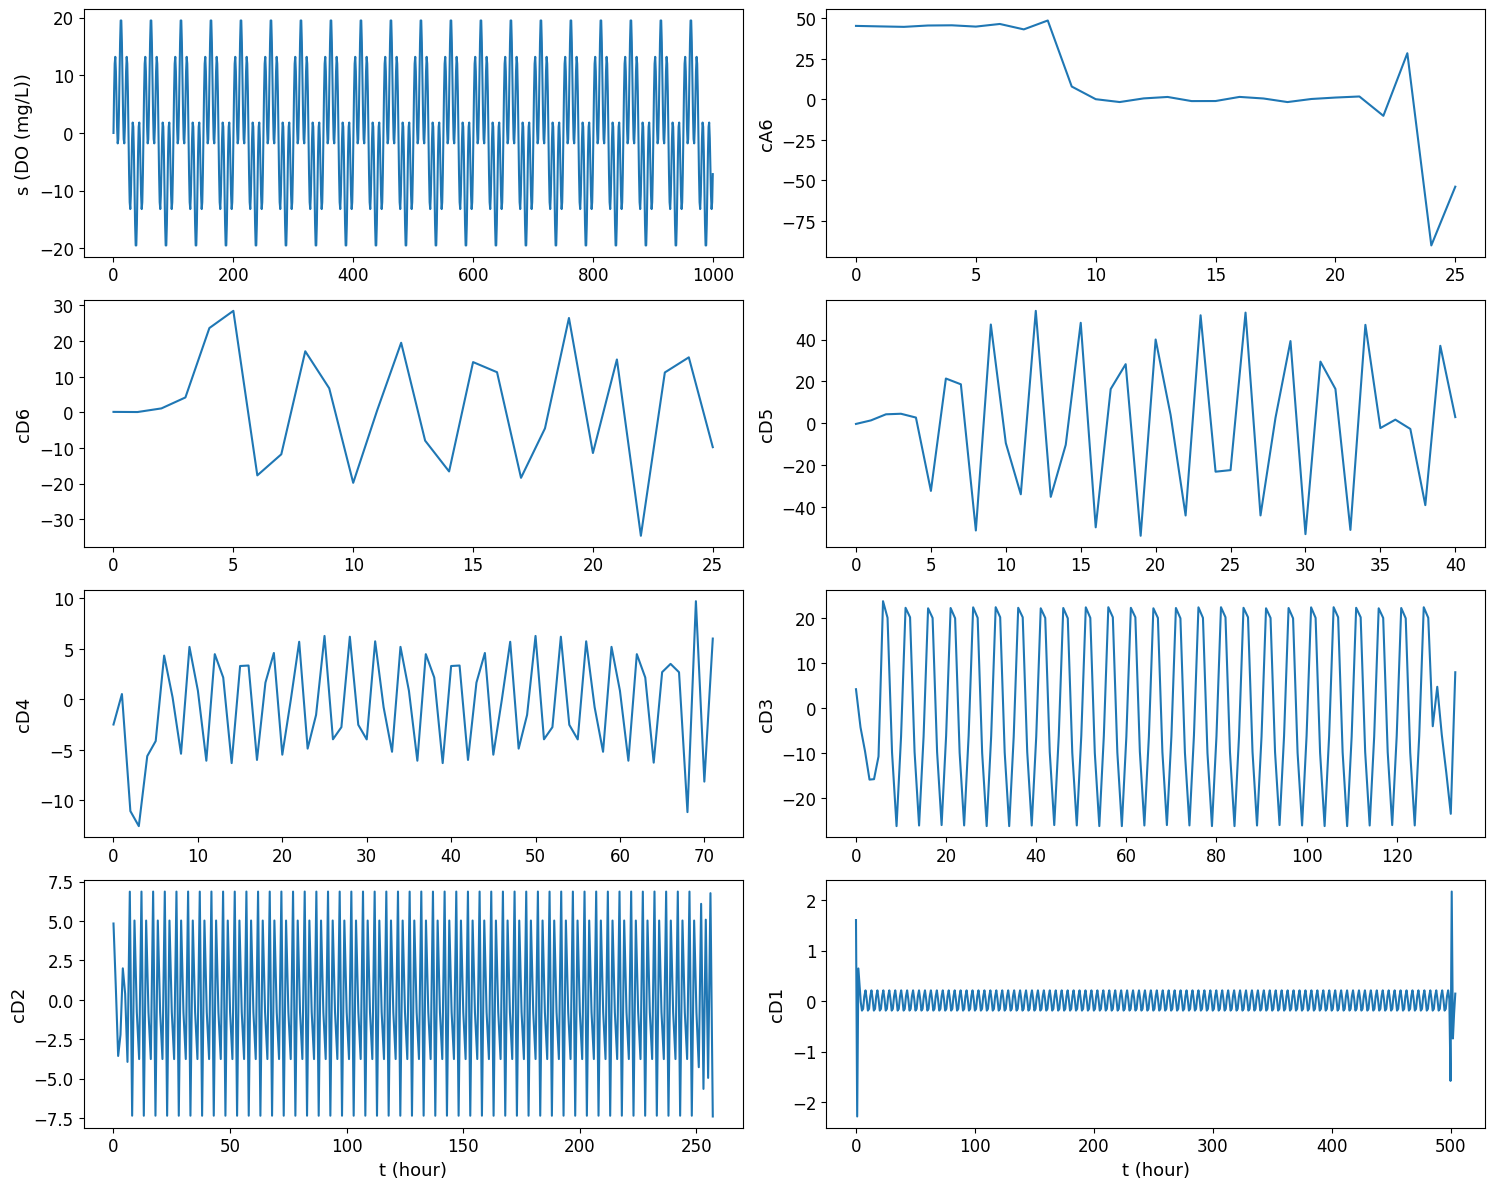

In [15]:
fig,axs = plt.subplots(4,2,figsize=(15,12))
plt.rc('xtick',labelsize=12)
plt.rc('ytick',labelsize=12)
axs[0,0].plot(x3)
axs[0,0].set_ylabel('s (DO (mg/L))',fontsize=13)
axs[0,1].plot(cA6)
axs[0,1].set_ylabel('cA6',fontsize=13)
axs[1,0].plot(cD6)
axs[1,0].set_ylabel('cD6',fontsize=13)
axs[1,1].plot(cD5)
axs[1,1].set_ylabel('cD5',fontsize=13)
axs[2,0].plot(cD4)
axs[2,0].set_ylabel('cD4',fontsize=13)
axs[2,1].plot(cD3)
axs[2,1].set_ylabel('cD3',fontsize=13)
axs[3,0].plot(cD2)
axs[3,0].set_ylabel('cD2',fontsize=13)
axs[3,0].set_xlabel('t (hour)',fontsize=13)
axs[3,1].plot(cD1)
axs[3,1].set_ylabel('cD1',fontsize=13)
axs[3,1].set_xlabel('t (hour)',fontsize=13)
plt.tight_layout()
plt.show()

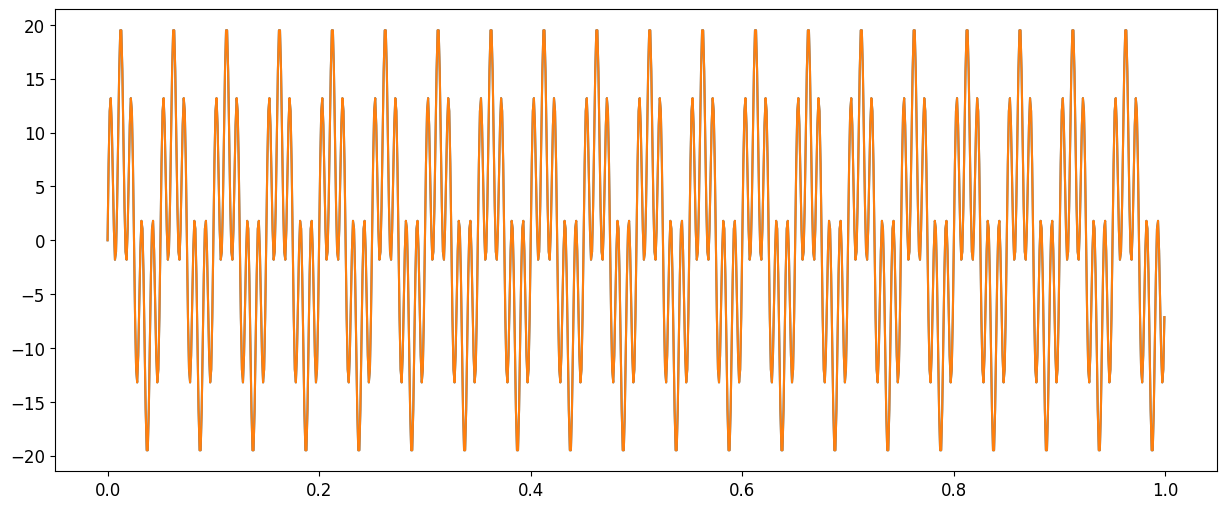

In [16]:
s_r = pywt.waverec(coeffs,'db6','sym')

fig,ax = plt.subplots(figsize=(15,6))
ax.plot(t,x3)
ax.plot(t,s_r)
plt.show()


In [17]:
cA06 = np.zeros(len(cA6))
cD06 = np.zeros(len(cD6))
cD05 = np.zeros(len(cD5))
cD04 = np.zeros(len(cD4))
cD03 = np.zeros(len(cD3))
cD02 = np.zeros(len(cD2))
cD01 = np.zeros(len(cD1))


In [18]:
A6 = pywt.waverec((cA6,cD06,cD05,cD04,cD03,cD02,cD01),'db6','sym')
D6 = pywt.waverec((cA06,cD6,cD05,cD04,cD03,cD02,cD01),'db6','sym')
D5 = pywt.waverec((cA06,cD06,cD5,cD04,cD03,cD02,cD01),'db6','sym')
D4 = pywt.waverec((cA06,cD06,cD05,cD4,cD03,cD02,cD01),'db6','sym')
D3 = pywt.waverec((cA06,cD06,cD05,cD04,cD3,cD02,cD01),'db6','sym')
D2 = pywt.waverec((cA06,cD06,cD05,cD04,cD03,cD2,cD01),'db6','sym')
D1 = pywt.waverec((cA06,cD06,cD05,cD04,cD03,cD02,cD1),'db6','sym')


In [19]:
A6 = A6[:-1]
D6 = D6[:-1]
D5 = D5[:-1]
D4 = D4[:-1]
D3 = D3[:-1]
D2 = D2[:-1]
D1 = D1[:-1]


In [20]:
A5 = A6 + D6
A4 = A6 + D6 + D5
A3 = A6 + D6 + D5 + D4
A2 = A6 + D6 + D5 + D4 + D3
A1 = A6 + D6 + D5 + D4 + D3 + D2

In [21]:
s_r = A6 + D6 + D5 + D4 + D3 + D2 + D1


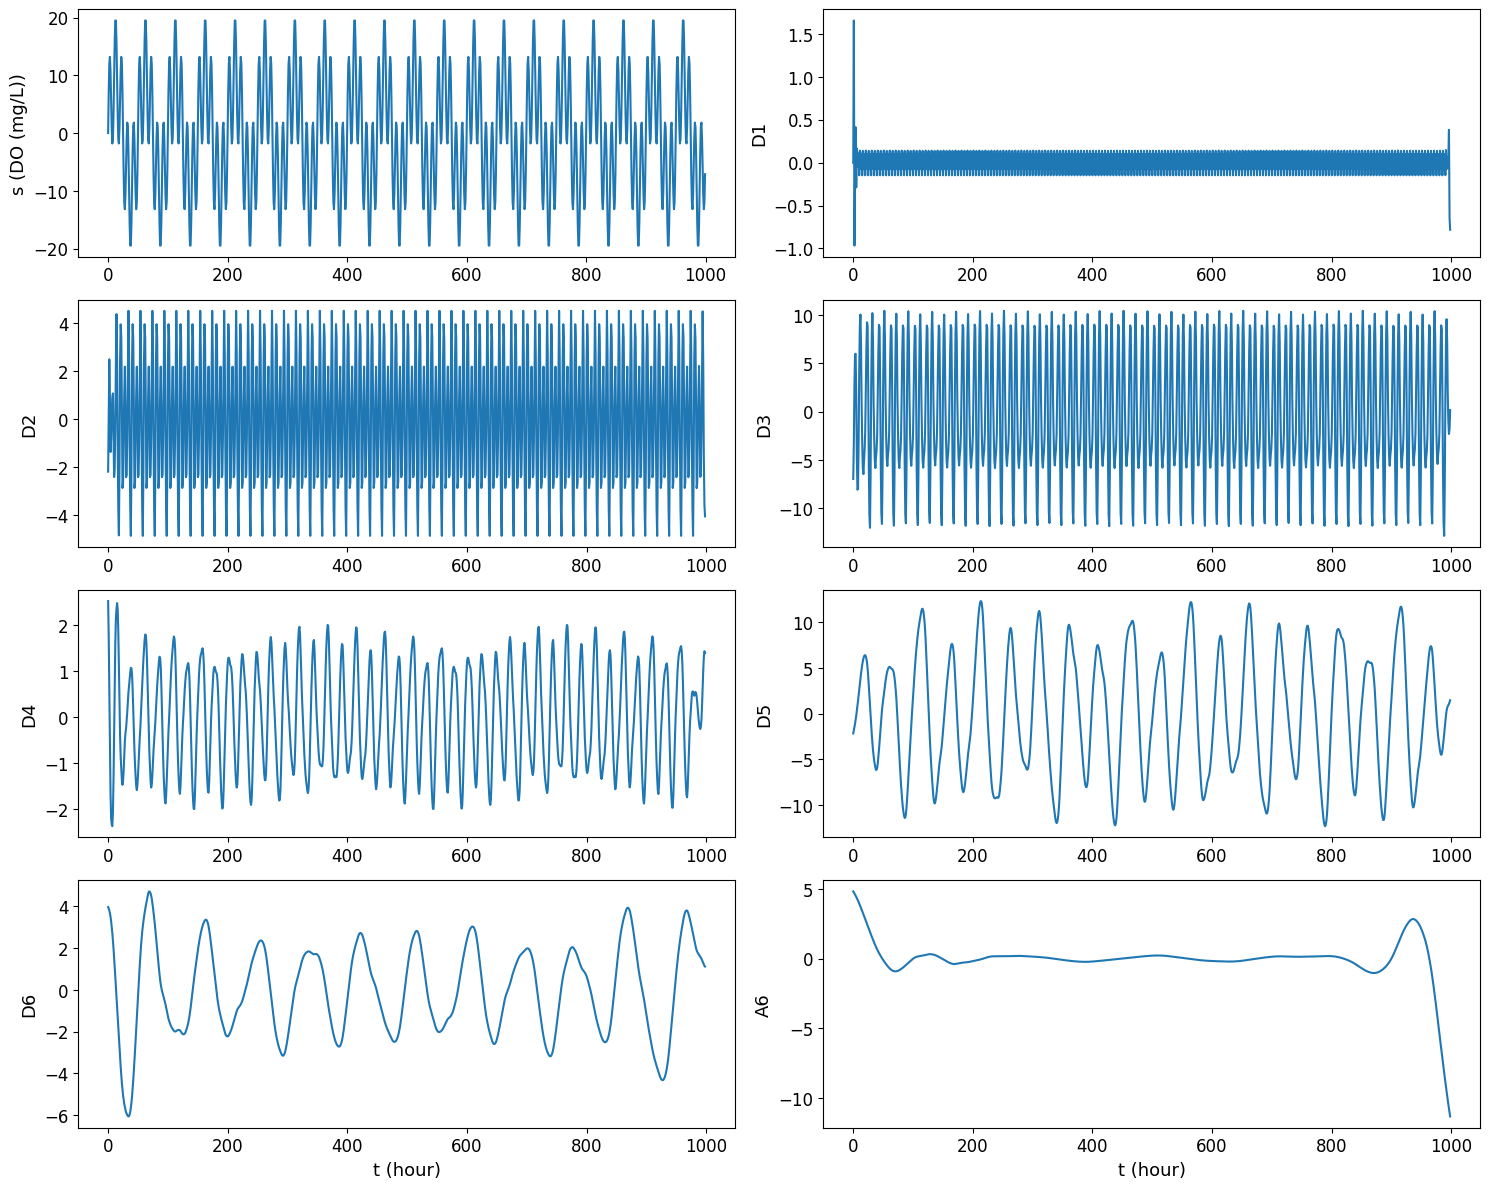

In [23]:
fig,axs = plt.subplots(4,2,figsize=(15,12))
plt.rc('xtick',labelsize=12)
plt.rc('ytick',labelsize=12)
axs[0,0].plot(x3)
axs[0,0].set_ylabel('s (DO (mg/L))',fontsize=13)
axs[0,1].plot(D1)
axs[0,1].set_ylabel('D1',fontsize=13)
axs[1,0].plot(D2)
axs[1,0].set_ylabel('D2',fontsize=13)
axs[1,1].plot(D3)
axs[1,1].set_ylabel('D3',fontsize=13)
axs[2,0].plot(D4)
axs[2,0].set_ylabel('D4',fontsize=13)
axs[2,1].plot(D5)
axs[2,1].set_ylabel('D5',fontsize=13)
axs[3,0].plot(D6)
axs[3,0].set_ylabel('D6',fontsize=13)
axs[3,0].set_xlabel('t (hour)',fontsize=13)
axs[3,1].plot(A6)
axs[3,1].set_ylabel('A6',fontsize=13)
axs[3,1].set_xlabel('t (hour)',fontsize=13)
plt.tight_layout()
plt.show()

### noise reduction

In [24]:
A5 = A6 + D6
A4 = A6 + D6 + D5
A3 = A6 + D6 + D5 + D4
A2 = A6 + D6 + D5 + D4 + D3
A1 = A6 + D6 + D5 + D4 + D3 + D2


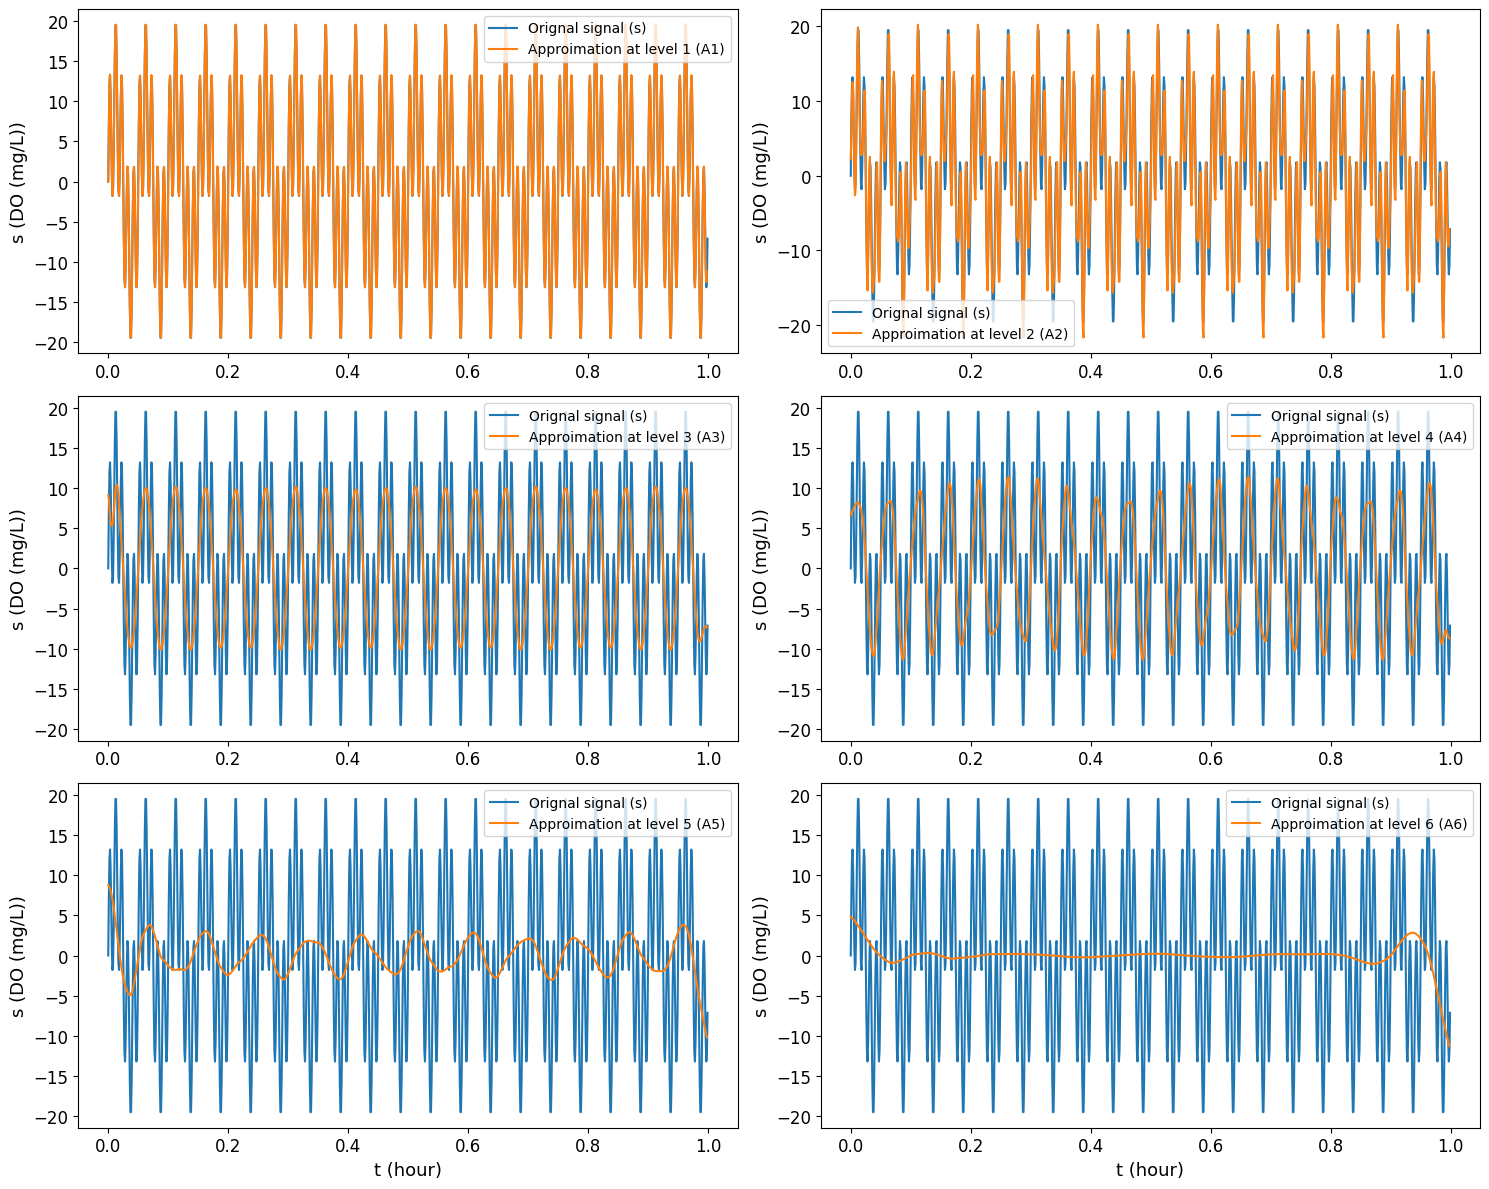

In [28]:
fig,axs = plt.subplots(3,2,figsize=(15,12))
plt.rc('xtick',labelsize=12)
plt.rc('ytick',labelsize=12)
axs[0,0].plot(t,x3)
axs[0,0].plot(t[:-1],A1)
axs[0,0].set_ylabel('s (DO (mg/L))',fontsize=13)
axs[0,0].legend(('Orignal signal (s)','Approimation at level 1 (A1)'),loc='best')

axs[0,1].plot(t,x3)
axs[0,1].plot(t[:-1],A2)
axs[0,1].set_ylabel('s (DO (mg/L))',fontsize=13)
axs[0,1].legend(('Orignal signal (s)','Approimation at level 2 (A2)'),loc='best')

axs[1,0].plot(t,x3)
axs[1,0].plot(t[:-1],A3)
axs[1,0].set_ylabel('s (DO (mg/L))',fontsize=13)
axs[1,0].legend(('Orignal signal (s)','Approimation at level 3 (A3)'),loc='best')

axs[1,1].plot(t,x3)
axs[1,1].plot(t[:-1],A4)
axs[1,1].set_ylabel('s (DO (mg/L))',fontsize=13)
axs[1,1].legend(('Orignal signal (s)','Approimation at level 4 (A4)'),loc='best')

axs[2,0].plot(t,x3)
axs[2,0].plot(t[:-1],A5)
axs[2,0].set_ylabel('s (DO (mg/L))',fontsize=13)
axs[2,0].legend(('Orignal signal (s)','Approimation at level 5 (A5)'),loc='best')

axs[2,0].set_xlabel('t (hour)',fontsize=13)
axs[2,1].plot(t,x3)
axs[2,1].plot(t[:-1],A6)
axs[2,1].set_ylabel('s (DO (mg/L))',fontsize=13)
axs[2,1].legend(('Orignal signal (s)','Approimation at level 6 (A6)'),loc='best')
axs[2,1].set_xlabel('t (hour)',fontsize=13)
plt.tight_layout()
plt.show()

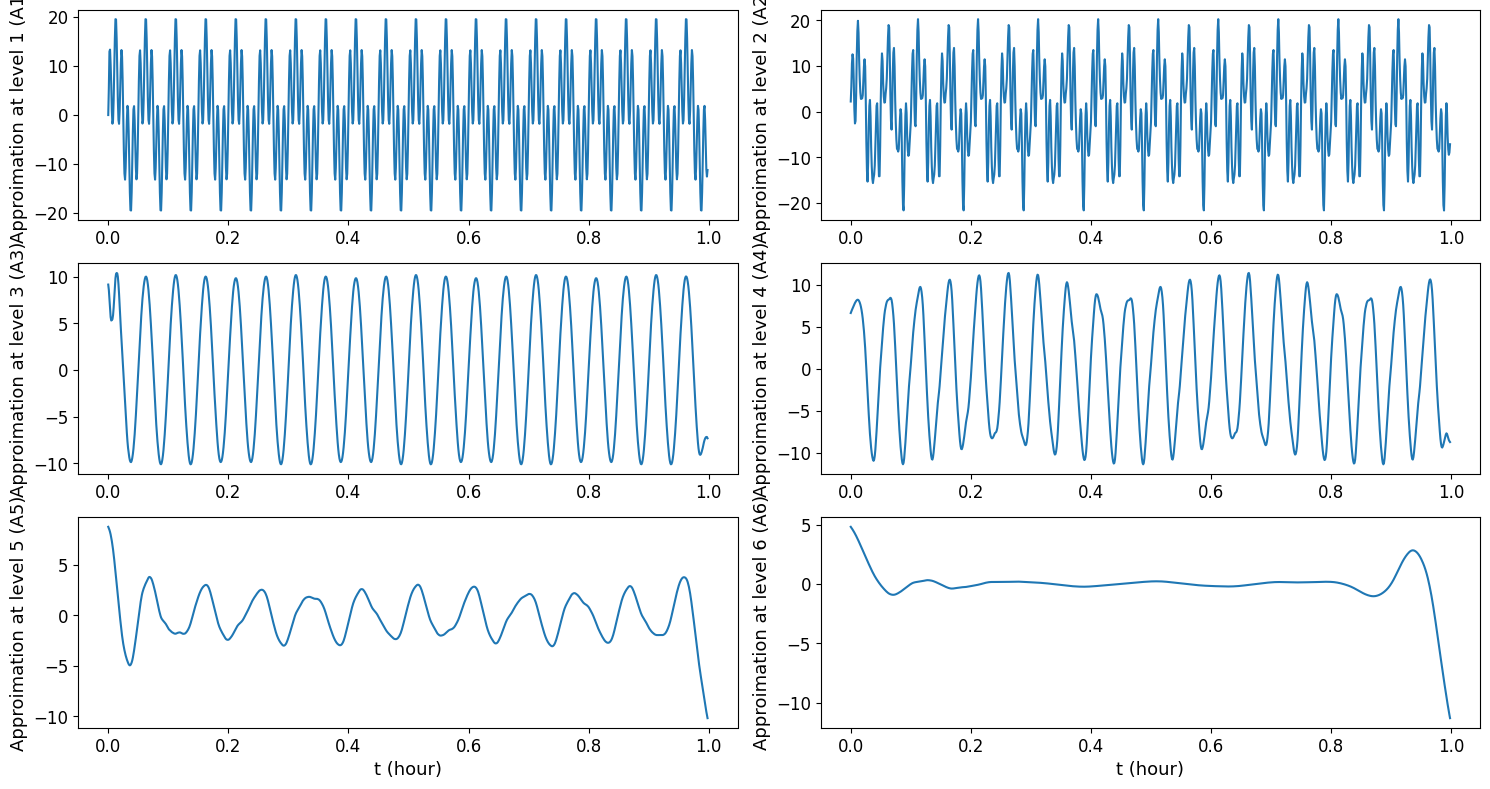

In [32]:
fig,axs = plt.subplots(3,2,figsize=(15,8))
plt.rc('xtick',labelsize=12)
plt.rc('ytick',labelsize=12)
#axs[0,0].plot(t,x3)
axs[0,0].plot(t[:-1],A1)
axs[0,0].set_ylabel('Approimation at level 1 (A1)',fontsize=13)
#axs[0,0].legend(('Approimation at level 1 (A1)'),loc='best')

#axs[0,1].plot(t,x3)
axs[0,1].plot(t[:-1],A2)
axs[0,1].set_ylabel('Approimation at level 2 (A2)',fontsize=13)
#axs[0,1].legend(('Approimation at level 2 (A2)'),loc='best')

#axs[1,0].plot(t,x3)
axs[1,0].plot(t[:-1],A3)
axs[1,0].set_ylabel('Approimation at level 3 (A3)',fontsize=13)
#axs[1,0].legend(('Approimation at level 3 (A3)'),loc='best')

#axs[1,1].plot(t,x3)
axs[1,1].plot(t[:-1],A4)
axs[1,1].set_ylabel('Approimation at level 4 (A4)',fontsize=13)
#axs[1,1].legend(('Approimation at level 4 (A4)'),loc='best')

#axs[2,0].plot(t,x3)
axs[2,0].plot(t[:-1],A5)
axs[2,0].set_ylabel('Approimation at level 5 (A5)',fontsize=13)
#axs[2,0].legend(('Approimation at level 5 (A5)'),loc='best')
axs[2,0].set_xlabel('t (hour)',fontsize=13)

#axs[2,1].plot(t,x3)
axs[2,1].plot(t[:-1],A6)
axs[2,1].set_ylabel('Approimation at level 6 (A6)',fontsize=13)
#axs[2,1].legend(('Approimation at level 6 (A6)'),loc='best')
axs[2,1].set_xlabel('t (hour)',fontsize=13)
plt.tight_layout()
plt.show()

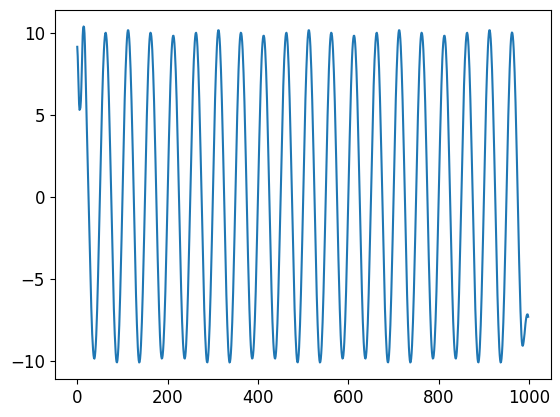

In [34]:
plt.plot(A3)

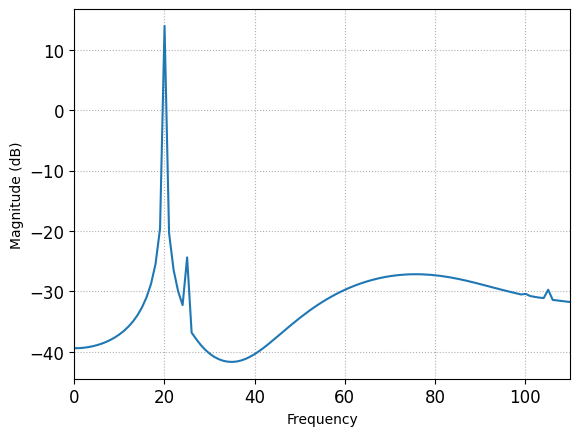

In [36]:
plt.magnitude_spectrum(A3, Fs=Fs, window=np.ones(A3.shape),scale="dB")# , sides='twosided')
plt.xlim(0,110)
#plt.ylim(-400,100)
plt.grid(ls=":")
plt.show()

## Filtrado por wavelets

### Single-level Wavelet Decomposition


#####  1D single-level DWT


In [ ]:
(cA,cD) = pywt.dwt(x3,'db2','sym')

In [ ]:
print('Length of orignal signal: ',len(x3))
print('Length of Approximation Coefficient: ', len(cA))
print('Length of Detail Coefficient: ',len(cD))

Length of orignal signal:  1000
Length of Approximation Coefficient:  501
Length of Detail Coefficient:  501


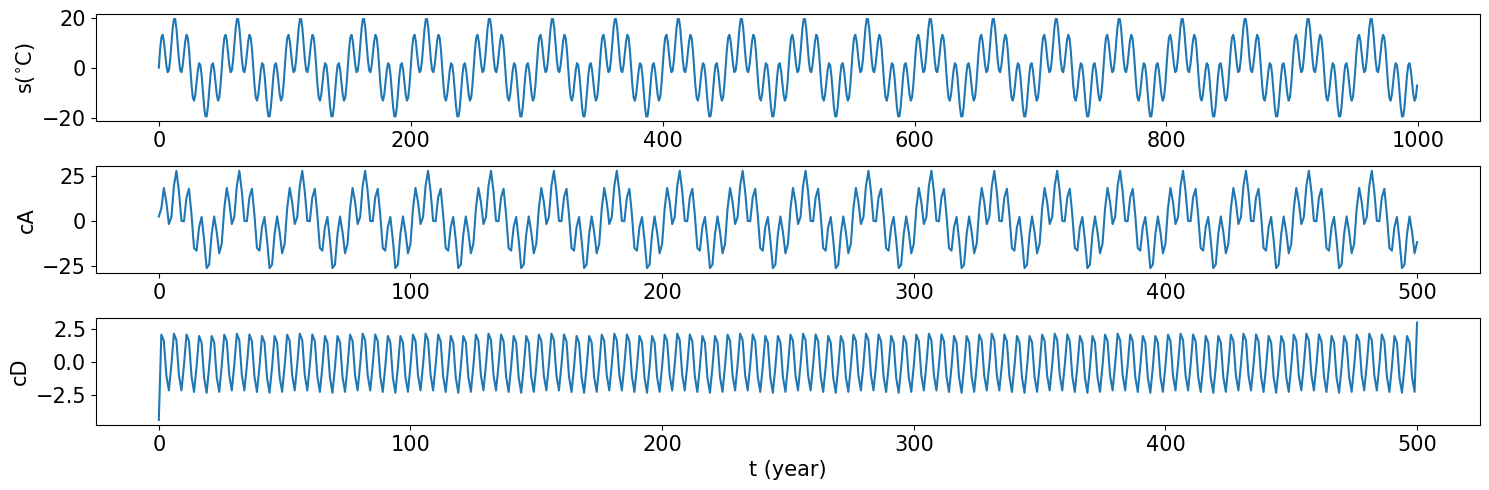

In [ ]:
# Reconstruct the Signal, inverse discrete wavelet transform

fig,axs = plt.subplots(3,1,figsize=(15,5))
plt.rc('xtick',labelsize=15)
plt.rc('ytick',labelsize=15)
axs[0].plot(x3)
axs[0].set_ylabel('s($^{\circ}$C)',fontsize=15)
axs[1].plot(cA)
axs[1].set_ylabel('cA',fontsize=15)
axs[2].plot(cD)
axs[2].set_ylabel('cD',fontsize=15)
axs[2].set_xlabel('t (year)',fontsize=15)

plt.tight_layout()
plt.show()

#### . Reconstruct the Signal

In [ ]:
s_r = pywt.idwt(cA,cD,'db2','sym')

In [ ]:
print('Length of orignial signal: ',len(x3))
print('Length of reconstructed signal: ',len(s_r))

Length of orignial signal:  1000
Length of reconstructed signal:  998


In [ ]:
s_r = s_r[:-1]

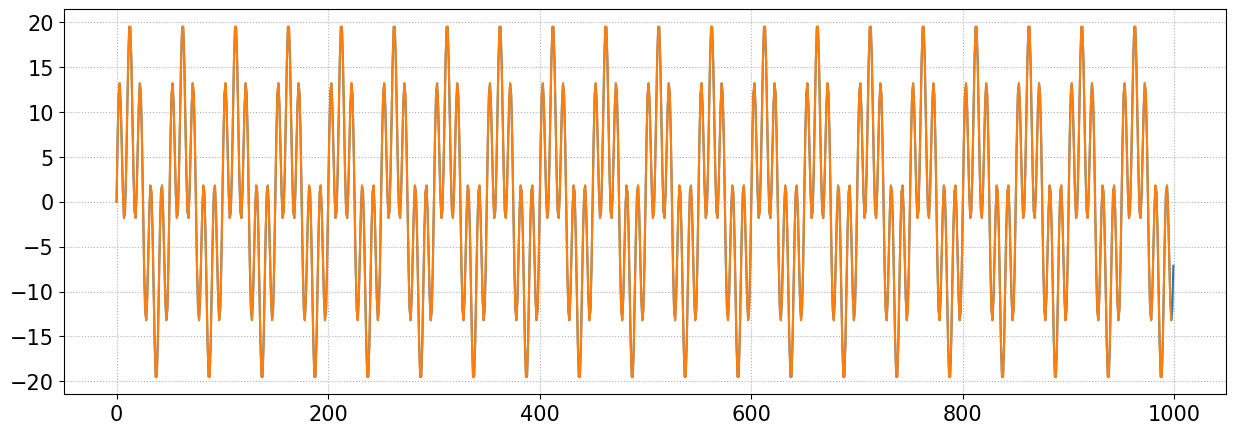

In [ ]:
plt.figure(figsize=(15,5))
plt.plot(x3)
plt.plot(s_r)
plt.grid(ls=":")

#### Partial Wavelet Reconstruction

##### Methodo 1

In [ ]:
# Method 1: upcoef method

A = pywt.upcoef('a',cA,'db2',level=1,take=len(x3))
D = pywt.upcoef('d',cD,'db2',level=1,take=len(x3))

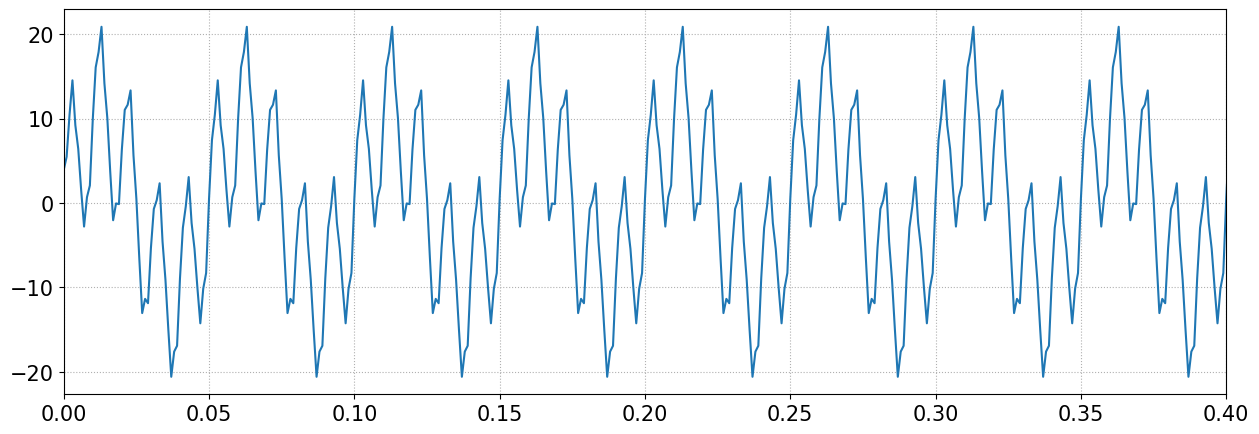

In [ ]:
plt.figure(figsize=(15,5))
plt.plot(t[:-1],A)
plt.grid(ls=":")
plt.xlim(0,0.4)
plt.show()

In [ ]:
# Reconstruct signal from the approximation and details
# from method 1
s_r = A + D
print(len(x3))
print(len(s_r))



1000
1000


##### Methodo 2

In [ ]:
# Method 2: inverse discrete wavelet transform

A1 = pywt.idwt(cA, None,'db2','sym')
D1 = pywt.idwt(None, cD, 'db2','sym')

In [ ]:
#  from method 2
s1_r = A1 + D1
print(len(s1_r))


1000


In [ ]:
s1_r = s1_r[:-1]

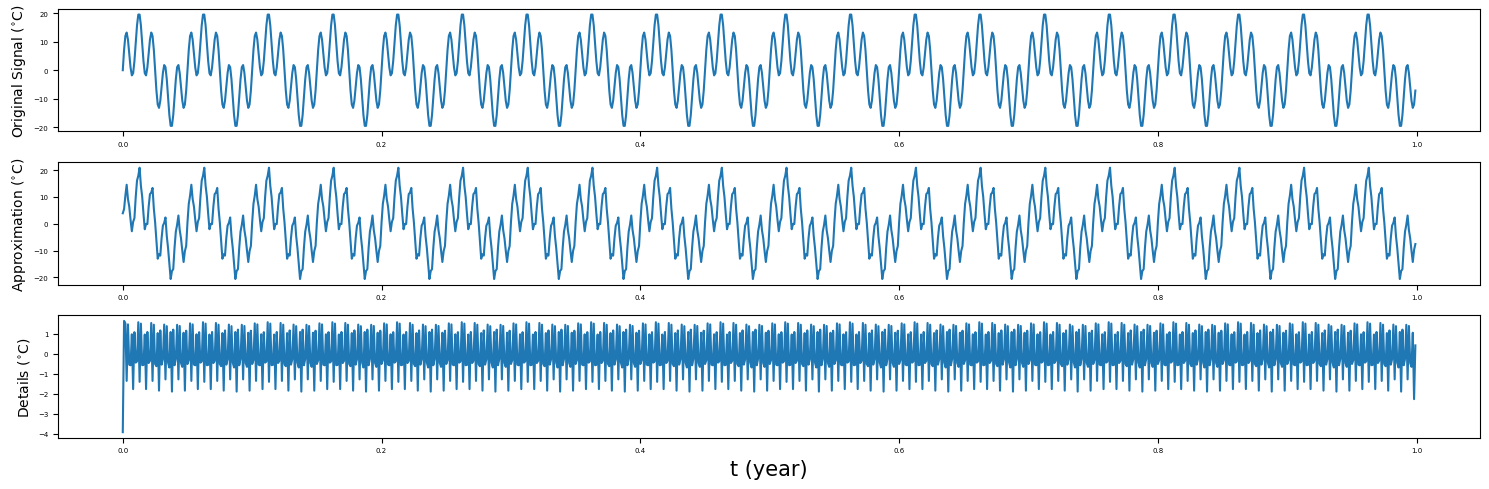

In [ ]:
# Visualization of Signal Approximation and Details

fig,(ax1,ax2,ax3) = plt.subplots(3,1,figsize=(15,5))
plt.rc('xtick',labelsize=5)
plt.rc('ytick',labelsize=5)
ax1.plot(t,x3)
ax1.set_ylabel('Original Signal ($^{\circ}$C)',fontsize=10)
ax2.plot(t,A)
ax2.set_ylabel('Approximation ($^{\circ}$C)',fontsize=10)
ax3.plot(t,D)
ax3.set_ylabel('Details ($^{\circ}$C)',fontsize=10)
ax3.set_xlabel('t (year)',fontsize=15)
plt.tight_layout()
plt.show()

### Noise Reduction

Detail constinuent is the high frequency data, which can be removed as noise.

- just keep the Approximation constituent
- just reconstruct the Approximation constituent


In [ ]:
A = pywt.upcoef('a',cA,'db2',level=1,take=len(s))


In [ ]:
A = pywt.idwt(cA, None,'db2','sym')
A = A[:-1]

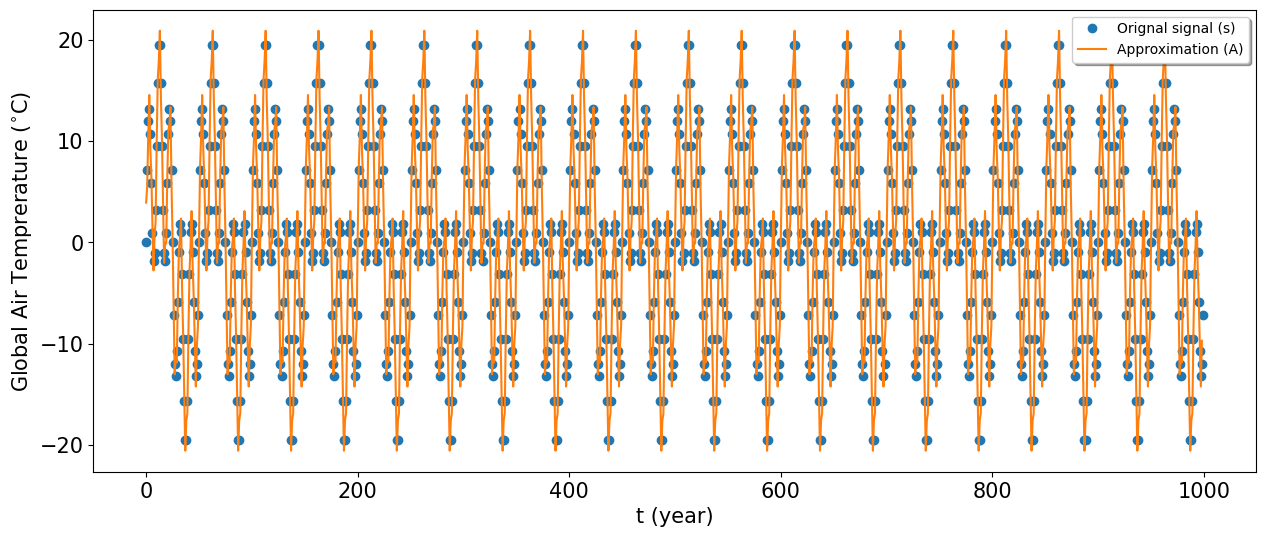

In [ ]:
fig,ax = plt.subplots(figsize=(15,6))
plt.rc('xtick',labelsize=15)
plt.rc('ytick',labelsize=15)
ax.plot(x3,'o')
ax.plot(A)
ax.set_ylabel('Global Air Temprerature ($^{\circ}$C)',fontsize=15)
ax.set_xlabel('t (year)',fontsize=15)
ax.legend(('Orignal signal (s)','Approximation (A)'),loc='best',shadow=True)

plt.show()